In [ ]:
#run bef_dgea.ipynb and run dgea.R before this code

In [1]:
from ete3 import Tree
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [ ]:

dge_df = pd.read_csv("mast_results_26_sep.csv")


,primerid,Pr(>Chisq),coef,FDR
0,A2ML1,2.287056e-20,-0.039610,2.650387e-20
1,A4GALT,2.592160e-06,-0.013816,2.675779e-06
2,AAAS,1.847481e-32,0.005949,2.431886e-32
3,AACS,2.573592e-22,-0.035098,3.032184e-22
4,AAGAB,2.174849e-67,-0.043781,4.356338e-67


In [ ]:
# Sort by absolute values of 'group1_logfoldchanges'
df_sorted = dge_df.reindex(dge_df['FDR'].abs().sort_values(ascending=False).index)



     primerid  Pr(>Chisq)      coef       FDR
4819    MYBL2    0.975219  0.000096  0.975219
3681     IRX2    0.948436 -0.001115  0.948539
4732     MSLN    0.805831 -0.001882  0.806007
4449     MEST    0.766642 -0.000058  0.766893
1967     DIO2    0.762048  0.000638  0.762380
...       ...         ...       ...       ...
6695     RPS9    0.000000  0.472418  0.000000
6694     RPS8    0.000000  0.525238  0.000000
6684     RPS6    0.000000  0.743547  0.000000
6683     RPS5    0.000000  0.480215  0.000000
6617     RPL3    0.000000  0.644165  0.000000

[9184 rows x 4 columns]


In [ ]:
import os
from ete3 import Tree
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.io import mmread

# =============================================================================
# 0. Global figure settings
# =============================================================================

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Arial'

# Make results folder
os.makedirs("results", exist_ok=True)

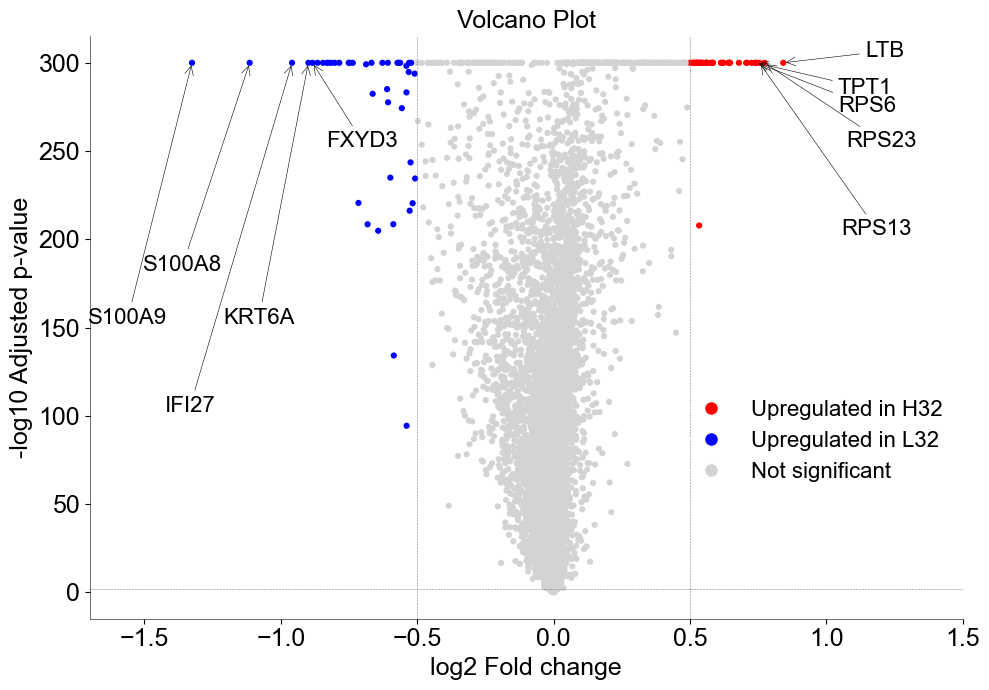

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- Parameters ---
logfc_thresh = 0.5
pval_thresh = 0.01

# Prepare dataframe
df = dge_df.copy()
df.columns = ['gene', 'pval_adj', 'logfc', 'FDR']

# Avoid -log10(0)
pval_safe = df['pval_adj'].clip(lower=1e-300)
df['-log10(pval)'] = -np.log10(pval_safe)

# Assign significance colors based on cutoffs
def volcano_color(row):
    if row['pval_adj'] < pval_thresh:
        if row['logfc'] > logfc_thresh:
            return 'red'    # upregulated
        elif row['logfc'] < -logfc_thresh:
            return 'blue'   # downregulated
    return 'lightgray'       # not significant

df['color'] = df.apply(volcano_color, axis=1)

# Volcano plot
plt.figure(figsize=(10, 7))
plt.scatter(df['logfc'], df['-log10(pval)'], c=df['color'], s=20, edgecolor='none')

# Cutoff lines
plt.axhline(-np.log10(pval_thresh), linestyle='--', color='gray', lw=0.4)
plt.axvline(-logfc_thresh, linestyle='--', color='gray', lw=0.4)
plt.axvline(logfc_thresh, linestyle='--', color='gray', lw=0.4)

# ---- Annotate top genes with manual offsets ----
top_up = df.sort_values('logfc', ascending=False).head(5)
top_down = df.sort_values('logfc', ascending=True).head(5)
top_genes = pd.concat([top_up, top_down])

# ✏️ manually set offsets (x_offset, y_offset) per gene name
# positive x_offset = move label right, negative = left
# positive y_offset = move label up, negative = down
manual_offsets = {
    # Upregulated genes
    top_up.iloc[0]['gene']: (0.3, 1),
    top_up.iloc[1]['gene']: (0.3, -50),
    top_up.iloc[2]['gene']: (0.3, -100),
    top_up.iloc[3]['gene']: (0.3, -30),
    top_up.iloc[4]['gene']: (0.3, -20),
    # Downregulated genes
    top_down.iloc[0]['gene']: (-0.09, -150),
    top_down.iloc[1]['gene']: (-0.1, -120),
    top_down.iloc[2]['gene']: (-0.28, -200),
    top_down.iloc[3]['gene']: (-0.05, -150),
    top_down.iloc[4]['gene']: (0.05, -50)
}

for _, row in top_genes.iterrows():
    x_offset, y_offset = manual_offsets.get(row['gene'], (0.2, 2))
    plt.annotate(
        row['gene'],
        xy=(row['logfc'], row['-log10(pval)']),  # arrow end = point of interest
        xytext=(row['logfc'] + x_offset, row['-log10(pval)'] + y_offset),
        textcoords='data',
        fontsize=16,
        arrowprops=dict(arrowstyle='->', color='black', lw=0.4),
        ha='left' if x_offset > 0 else 'right',
        va='bottom'
    )

# Custom legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Upregulated in H32',
           markerfacecolor='red', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Upregulated in L32',
           markerfacecolor='blue', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Not significant',
           markerfacecolor='lightgray', markersize=10)
]
plt.legend(handles=legend_elements, loc='lower right', bbox_to_anchor=(1, 0.2), frameon=False, fontsize=16)

# Labels and title
plt.title("Volcano Plot", fontsize=18)
plt.xlabel("log2 Fold change", fontsize=18)
plt.ylabel("-log10 Adjusted p-value", fontsize=18)
plt.xlim(-1.7, 1.5)
plt.tick_params(axis="y", labelsize=18)
plt.tick_params(axis="x", labelsize=18)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# Thin bottom/left axis lines
ax.spines["bottom"].set_linewidth(0.4)
ax.spines["left"].set_linewidth(0.4)


plt.tight_layout()
plt.savefig("volcano_plot_manual_arrows.pdf", dpi=300)
plt.show()


In [ ]:
sig_genes_df = df[df['significant']][['gene', 'logfc', 'pval_adj']].sort_values(by='pval_adj')

In [ ]:

# Then display your full table
sig_genes_df = sig_genes_df[sig_genes_df['logfc'] < 0].sort_values(by='logfc', ascending=False)


In [18]:
import gseapy as gp

# Input: list of gene names (e.g., from sig_genes_df['gene'].tolist())
gene_list = sig_genes_df['gene'].tolist()

# Enrichment analysis (e.g., GO Biological Process)
enr = gp.enrichr(gene_list=gene_list,
                 gene_sets='GO_Biological_Process_2021',
                 organism='Human',  # or 'Mouse'
                 outdir=None,  # no files saved
                 cutoff=0.05)

# View results
print(enr.results.head())


                     Gene_set  \
0  GO_Biological_Process_2021   
1  GO_Biological_Process_2021   
2  GO_Biological_Process_2021   
3  GO_Biological_Process_2021   
4  GO_Biological_Process_2021   

                                                Term Overlap       P-value  \
0              neutrophil degranulation (GO:0043312)  23/481  6.232638e-13   
1  neutrophil activation involved in immune respo...  23/485  7.397004e-13   
2          neutrophil mediated immunity (GO:0002446)  23/488  8.401852e-13   
3                      skin development (GO:0043588)   10/80  2.925307e-10   
4          keratinocyte differentiation (GO:0030216)    7/41  1.586777e-08   

   Adjusted P-value  Old P-value  Old Adjusted P-value  Odds Ratio  \
0      4.478187e-10            0                     0    8.050706   
1      4.478187e-10            0                     0    7.979357   
2      4.478187e-10            0                     0    7.926651   
3      1.169391e-07            0                    

In [71]:
enr.results['-log10(Adjusted P-value)'] = -np.log10(enr.results['Adjusted P-value'] + 1e-10)


In [72]:
df_plot = enr.results.sort_values('Adjusted P-value')


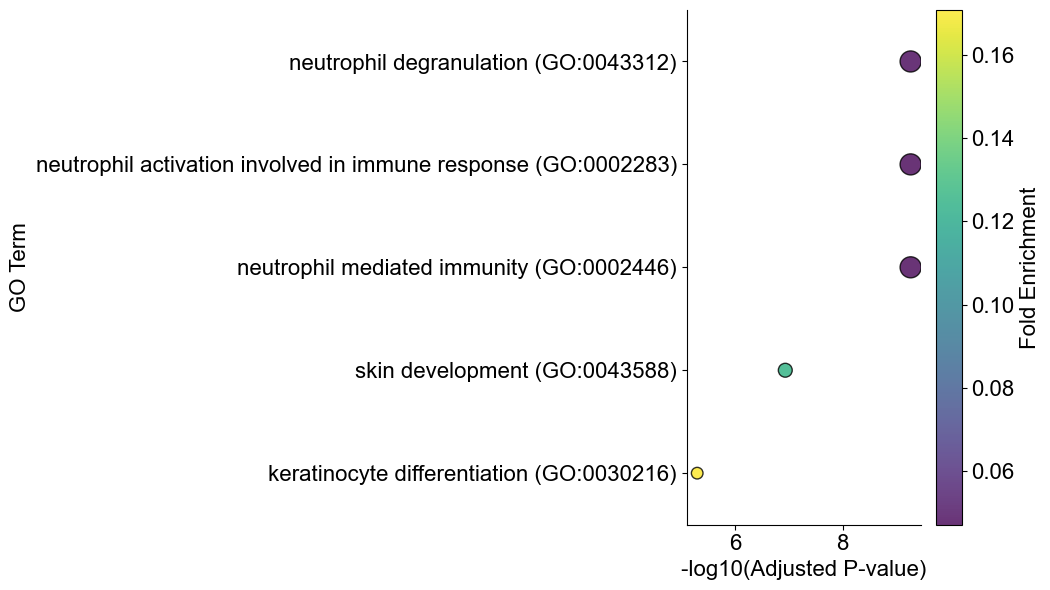

In [ ]:

# Assuming enr.results has 'Gene Count' and 'Overlap'
df = enr.results.copy()

# The total number of genes in your gene list
total_genes_in_list = len(gene_list)

# Parse overlap column
df['Gene Count'] = df['Overlap'].str.split('/').str[0].astype(int)
df['GO Term Total Genes'] = df['Overlap'].str.split('/').str[1].astype(int)

# Calculate fold enrichment
df['Fold Enrichment'] = (
    (df['Gene Count'] / len(gene_list)) /
    (df['GO Term Total Genes'] / total_genes_in_list)
)

# Calculate -log10(p-value)
df['-log10(Adjusted P-value)'] = -np.log10(df['Adjusted P-value'] + 1e-10)

# Select top N GO terms
top_n = 5
df_plot = df.sort_values('Adjusted P-value').head(top_n)

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    x=df_plot['-log10(Adjusted P-value)'],
    y=df_plot['Term'],
    s=df_plot['Gene Count'] * 10,
    c=df_plot['Fold Enrichment'],
    cmap='viridis',
    edgecolor='black',
    alpha=0.8
)

# Labels and title
plt.xlabel('-log10(Adjusted P-value)', fontsize=16)
plt.ylabel('GO Term', fontsize=16)


# Tick sizes
plt.tick_params(axis='x', labelsize=16)
plt.tick_params(axis='y', labelsize=16)

# Colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Fold Enrichment', fontsize=16)
cbar.ax.tick_params(labelsize=16)

# Invert y-axis
plt.gca().invert_yaxis()

# Paper-style axes
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)
ax.tick_params(axis='both', which='both', width=0.8)
ax.tick_params(top=False, right=False)
ax.set_ylim(len(df_plot) - 0.5, -0.5)


plt.tight_layout()

plt.savefig("GO_enrichment_dotplot.pdf", dpi=300)
# Optional: save as PDF
# plt.savefig("GO_enrichment_dotplot.pdf", bbox_inches="tight")

plt.show()
